# Quantum AI in Practice: Tools, Hardware, Noise, Error Correction, Industry and Post-Quantum Cryptography

> **Who is this for:** AI engineers who have done notebooks 01-03 (or know the basics) and now want the practical picture: which tools to use, what the hardware looks like, why noise is the central problem, where AI helps quantum computing, which industry use cases are realistic, and why **post-quantum cryptography** matters for AI systems today.
>
> **What you will learn:**
> - **Qiskit** and **PennyLane** versions of a Bell state, a Grover run and a tiny variational classifier (and how they compare with our numpy simulator); Cirq and other tools
> - the main **hardware modalities**: superconducting, trapped ion, neutral atom, photonic, spin and topological qubits
> - **noise and decoherence**, with a simulated **depolarizing-noise demo** on the Bell state, readout errors, and **error mitigation** (zero-noise extrapolation)
> - **quantum error correction**: physical vs logical qubits, the repetition code and the **threshold** idea, the **surface code**, and the below-threshold results reported since 2024
> - **AI for quantum** (neural decoders, reinforcement learning for control, LLMs for quantum code) vs **quantum for AI**, with a small learned-decoder demo
> - realistic **industry use cases** (chemistry and materials, optimisation, finance) with honest caveats
> - **post-quantum cryptography**: the NIST standards ML-KEM and ML-DSA, "harvest now, decrypt later", a toy lattice (LWE) example, and why AI engineers should care
> - how to try **real hardware via the cloud** (IBM Quantum, Amazon Braket, Azure Quantum) and a **career / learning roadmap**
>
> **Prerequisites:** [01_quantum_computing_basics.ipynb](01_quantum_computing_basics.ipynb), [02_quantum_algorithms.ipynb](02_quantum_algorithms.ipynb), [03_quantum_machine_learning.ipynb](03_quantum_machine_learning.ipynb).
>
> **Time needed:** about 2-3 hours. The notebook runs in under a minute.
>
> **Runs on:** CPU, no API key, no internet. The core cells use only numpy, scikit-learn and matplotlib. The optional Qiskit and PennyLane cells run if the libraries are installed (`pip install qiskit pennylane`) and print "skipped" otherwise. Nothing is sent to real quantum hardware.

## 0. Setup

Core imports, a fixed seed, our numpy simulator from notebook 01, and **guarded imports** for the optional libraries: if a library is missing, the related cells print a "skipped" message instead of crashing.

In [1]:
import time, warnings
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from scipy.optimize import minimize

warnings.filterwarnings("ignore", category=DeprecationWarning)
SEED = 42
rng = np.random.default_rng(SEED)
np.set_printoptions(precision=3, suppress=True)

try:
    import qiskit
    from qiskit import QuantumCircuit
    from qiskit.circuit import ParameterVector
    from qiskit.quantum_info import Statevector, SparsePauliOp
    from qiskit.primitives import StatevectorSampler, StatevectorEstimator
    HAVE_QISKIT = True
    print("qiskit", qiskit.__version__)
except ImportError:
    HAVE_QISKIT = False
    print("skipped: pip install qiskit  (Qiskit cells will be skipped)")

try:
    import pennylane as qml
    from pennylane import numpy as pnp
    HAVE_PENNYLANE = True
    print("pennylane", qml.__version__)
except ImportError:
    HAVE_PENNYLANE = False
    print("skipped: pip install pennylane  (PennyLane cells will be skipped)")

qiskit 2.6.2


pennylane 0.45.1


In [2]:
# ---- The tiny statevector simulator from notebook 01 (same code, in one cell) ----
from collections import Counter

# Single-qubit gates (2x2 matrices)
I2 = np.eye(2, dtype=complex)
X = np.array([[0, 1], [1, 0]], dtype=complex)
Y = np.array([[0, -1j], [1j, 0]], dtype=complex)
Z = np.array([[1, 0], [0, -1]], dtype=complex)
H = np.array([[1, 1], [1, -1]], dtype=complex) / np.sqrt(2)
S = np.array([[1, 0], [0, 1j]], dtype=complex)
T = np.array([[1, 0], [0, np.exp(1j * np.pi / 4)]], dtype=complex)

def RX(t): return np.array([[np.cos(t/2), -1j*np.sin(t/2)], [-1j*np.sin(t/2), np.cos(t/2)]], dtype=complex)
def RY(t): return np.array([[np.cos(t/2), -np.sin(t/2)], [np.sin(t/2), np.cos(t/2)]], dtype=complex)
def RZ(t): return np.array([[np.exp(-1j*t/2), 0], [0, np.exp(1j*t/2)]], dtype=complex)

# Two-qubit gates (4x4). The first qubit listed is the control.
CNOT = np.array([[1,0,0,0],[0,1,0,0],[0,0,0,1],[0,0,1,0]], dtype=complex)
CZ = np.diag([1, 1, 1, -1]).astype(complex)

def apply_gate(psi, U, qubits, n):
    """Apply matrix U to the listed qubits of an n-qubit state psi.
    Qubit 0 is the LEFT-most bit of a bitstring like '011'."""
    k = len(qubits)
    psi = psi.reshape([2] * n)
    U = U.reshape([2] * (2 * k))
    psi = np.tensordot(U, psi, axes=(list(range(k, 2 * k)), list(qubits)))
    psi = np.moveaxis(psi, list(range(k)), list(qubits))
    return psi.reshape(-1)

class QSim:
    """A tiny statevector simulator. Methods return self, so calls can be chained."""
    def __init__(self, n):
        self.n = n
        self.psi = np.zeros(2 ** n, dtype=complex)
        self.psi[0] = 1.0                      # start in |00...0>
    def gate(self, U, *qubits):
        self.psi = apply_gate(self.psi, U, qubits, self.n); return self
    def x(self, q):  return self.gate(X, q)
    def y(self, q):  return self.gate(Y, q)
    def z(self, q):  return self.gate(Z, q)
    def h(self, q):  return self.gate(H, q)
    def s(self, q):  return self.gate(S, q)
    def t(self, q):  return self.gate(T, q)
    def rx(self, th, q): return self.gate(RX(th), q)
    def ry(self, th, q): return self.gate(RY(th), q)
    def rz(self, th, q): return self.gate(RZ(th), q)
    def cx(self, c, t): return self.gate(CNOT, c, t)
    def cz(self, a, b): return self.gate(CZ, a, b)
    def probs(self):
        return np.abs(self.psi) ** 2
    def measure(self, shots=1000, seed=0):
        """Sample bitstrings like a real device would. Returns a Counter."""
        rng = np.random.default_rng(seed)
        p = self.probs(); p = p / p.sum()
        idx = rng.choice(len(p), size=shots, p=p)
        return Counter(format(i, f"0{self.n}b") for i in idx)

def bitstrings(n):
    return [format(i, f"0{n}b") for i in range(2 ** n)]

def plot_counts(counts, title="", ax=None):
    """Bar chart of measurement counts, with every bitstring on the x-axis."""
    n = len(next(iter(counts)))
    labels = bitstrings(n)
    if ax is None:
        _, ax = plt.subplots(figsize=(5, 2.6))
    ax.bar(labels, [counts.get(b, 0) for b in labels], color="tab:blue")
    ax.set_title(title); ax.set_ylabel("counts")
    ax.tick_params(axis="x", rotation=90 if n > 3 else 0)
    plt.tight_layout()
    return ax

def show_state(psi, tol=1e-9):
    """Print the non-zero amplitudes of a state in ket notation."""
    n = int(np.log2(len(psi)))
    for i, a in enumerate(psi):
        if abs(a) > tol:
            print(f"  |{format(i, f'0{n}b')}>  amplitude {a.real:+.3f}{a.imag:+.3f}j   probability {abs(a)**2:.3f}")

print("Simulator ready: QSim, apply_gate, gates X Y Z H S T RX RY RZ CNOT CZ, plot_counts, show_state")

Simulator ready: QSim, apply_gate, gates X Y Z H S T RX RY RZ CNOT CZ, plot_counts, show_state


## 1. The software landscape

**What it is.** A **quantum SDK** (software development kit) lets you write circuits in Python, simulate them, compile ("transpile") them for a specific device, and send them to cloud hardware.

**Simple analogy.** Like deep-learning frameworks: PyTorch and JAX describe the same maths with different styles, and compile to different chips. Quantum SDKs do the same for quantum chips.

| Tool | Made by | Best for | Notes (as of late 2026, stated generally) |
|---|---|---|---|
| **Qiskit** | IBM (open source) | general circuits, algorithms, IBM hardware | the most widely used SDK; "primitives" (Sampler, Estimator) are the main interface; Qiskit Aer for fast/noisy simulation |
| **PennyLane** | Xanadu (open source) | differentiable programming and QML | plugs into PyTorch/JAX; plugins for many hardware back-ends; large library of QML demos |
| **Cirq** | Google (open source) | low-level circuit control, Google-style hardware research | used with qsim (fast simulator) and Stim for error correction |
| **Amazon Braket SDK** | AWS | one API for several hardware vendors | pay-per-shot access to different modalities |
| **Azure Quantum / Q#** | Microsoft | resource estimation, several vendors | the Azure Quantum Resource Estimator is useful for "how many qubits would this need?" |
| **CUDA-Q** | NVIDIA | GPU-accelerated simulation, hybrid HPC + quantum workflows | C++ and Python |
| **pytket** | Quantinuum | compilation/optimisation across devices | strong circuit optimiser |
| **Stim** | open source (Google researchers) | very fast simulation of error-correction circuits | the standard tool for QEC research |
| **OpenQASM 3** | open standard | an assembly-like text format for circuits | lets tools exchange circuits |

**Which one should I pick?** For learning and general work: **Qiskit**. For quantum machine learning and gradients: **PennyLane**. Concepts transfer easily between them; this notebook shows the same three tasks in both.

## 2. Qiskit: Bell state, Grover and a tiny variational classifier

### 2.1 Bell state

**How it works.** Build a `QuantumCircuit`, inspect the exact state with `Statevector`, and sample measurement shots with the `StatevectorSampler` primitive (a local simulator with the same interface as the real-hardware sampler).

In [3]:
if not HAVE_QISKIT:
    print("skipped: pip install qiskit")
else:
    bell_qc = QuantumCircuit(2)
    bell_qc.h(0)
    bell_qc.cx(0, 1)
    print(bell_qc.draw(output="text"))
    print("exact probabilities:", {str(k): round(float(v), 3) for k, v in Statevector(bell_qc).probabilities_dict().items()})

    meas = bell_qc.copy(); meas.measure_all()
    counts_q = StatevectorSampler(seed=SEED).run([meas], shots=1000).result()[0].data.meas.get_counts()
    print("1000 shots:", counts_q)
    print("our numpy simulator:", QSim(2).h(0).cx(0, 1).measure(1000, seed=SEED))

     ┌───┐     
q_0: ┤ H ├──■──
     └───┘┌─┴─┐
q_1: ─────┤ X ├
          └───┘
exact probabilities: {'00': 0.5, '11': 0.5}
1000 shots: {'11': 497, '00': 503}
our numpy simulator: Counter({'00': 503, '11': 497})


### 2.2 Watch out: bit order

**Qiskit is "little-endian"**: in a printed bitstring, **qubit 0 is the right-most bit**. Our numpy simulator (and many textbooks) put qubit 0 on the **left**. The Bell state hides this because `00` and `11` read the same both ways. A single X on qubit 0 shows the difference.

In [4]:
if not HAVE_QISKIT:
    print("skipped: pip install qiskit")
else:
    qc = QuantumCircuit(3); qc.x(0)
    print("Qiskit, X on qubit 0:     ", [str(k) for k in Statevector(qc).probabilities_dict()])   # '001'
    print("our simulator, X on qubit 0:", [b for b, p in zip(bitstrings(3), QSim(3).x(0).probs()) if p > 0.5])  # '100'
    print("-> reverse the string to convert: '001'[::-1] =", "001"[::-1])

Qiskit, X on qubit 0:      ['001']
our simulator, X on qubit 0: ['100']
-> reverse the string to convert: '001'[::-1] = 100


### 2.3 Grover search in Qiskit

Same algorithm as notebook 02, now with real gates instead of a big oracle matrix. The marked item is "qubit 0 = 0, qubit 1 = 1, qubit 2 = 1" (`011` in our left-to-right notation, printed by Qiskit as `110`).
- **Oracle:** X gates turn the marked state into $\lvert111\rangle$, a **controlled-controlled-Z** (H, Toffoli, H) flips its sign, and the X gates are undone.
- **Diffuser:** H on all, X on all, controlled-controlled-Z, X on all, H on all.

In [5]:
def ccz(qc):
    qc.h(2); qc.ccx(0, 1, 2); qc.h(2)          # CCZ built from a Toffoli (CCX)

if not HAVE_QISKIT:
    print("skipped: pip install qiskit")
else:
    marked = {0: 0, 1: 1, 2: 1}                  # qubit -> bit value of the marked item
    grover_qc = QuantumCircuit(3)
    grover_qc.h([0, 1, 2])
    for _ in range(2):                           # 2 rounds is optimal for 8 items
        zeros = [q for q, bit in marked.items() if bit == 0]
        if zeros: grover_qc.x(zeros)             # oracle
        ccz(grover_qc)
        if zeros: grover_qc.x(zeros)
        grover_qc.h([0, 1, 2]); grover_qc.x([0, 1, 2])   # diffuser
        ccz(grover_qc)
        grover_qc.x([0, 1, 2]); grover_qc.h([0, 1, 2])
    print("gate counts:", dict(grover_qc.count_ops()))
    g_meas = grover_qc.copy(); g_meas.measure_all()
    counts_g = StatevectorSampler(seed=SEED).run([g_meas], shots=1000).result()[0].data.meas.get_counts()
    top = max(counts_g, key=counts_g.get)
    print(f"most common (Qiskit order): {top} -> in our order {top[::-1]}, {counts_g[top]} of 1000 shots")

gate counts: {'h': 23, 'x': 16, 'ccx': 4}
most common (Qiskit order): 110 -> in our order 011, 943 of 1000 shots


### 2.4 A tiny variational classifier in Qiskit

The same 2-qubit, 3-layer re-uploading circuit as notebook 03, written with Qiskit **parameters** (placeholders for numbers that are filled in later). The `StatevectorEstimator` primitive computes $\langle Z_0\rangle$ for all data points in one call (an array of parameter values), and SciPy's derivative-free COBYLA optimiser trains the 12 angles. In Qiskit's Pauli-string labels the right-most letter is qubit 0, so $Z_0$ is written `"IZ"`.

In [6]:
# Shared toy data for the Qiskit and PennyLane classifiers: 60 make_moons points
X_all, y_all = make_moons(n_samples=60, noise=0.15, random_state=SEED)
X_tr, X_te, y_tr, y_te = train_test_split(X_all, y_all, train_size=40, random_state=SEED, stratify=y_all)
sc = StandardScaler().fit(X_tr); X_tr, X_te = sc.transform(X_tr), sc.transform(X_te)
print("train", X_tr.shape, "test", X_te.shape)

train (40, 2) test (20, 2)


In [7]:
if not HAVE_QISKIT:
    print("skipped: pip install qiskit")
else:
    xp, wp = ParameterVector("x", 2), ParameterVector("w", 12)
    clf_qc = QuantumCircuit(2)
    for l in range(3):
        clf_qc.ry(xp[0], 0); clf_qc.ry(xp[1], 1)                    # data re-uploading
        clf_qc.ry(wp[4*l], 0); clf_qc.ry(wp[4*l+1], 1)              # trainable layer
        clf_qc.rz(wp[4*l+2], 0); clf_qc.rz(wp[4*l+3], 1)
        clf_qc.cx(0, 1)
    order = list(clf_qc.parameters)                                  # Qiskit sorts parameters by name
    print("parameter order:", [p.name for p in order][:3], "...", [p.name for p in order][-2:])
    estimator, z0 = StatevectorEstimator(), SparsePauliOp("IZ")

    def qiskit_expval(X, w):
        vals = np.hstack([np.tile(w, (len(X), 1)), X])               # columns follow `order`: w[0..11], x[0], x[1]
        return estimator.run([(clf_qc, z0, vals)]).result()[0].data.evs

    def qiskit_loss(w):
        p = np.clip((1 + qiskit_expval(X_tr, w)) / 2, 1e-7, 1 - 1e-7)
        return -np.mean(y_tr * np.log(p) + (1 - y_tr) * np.log(1 - p))

    t0 = time.time()
    res = minimize(qiskit_loss, rng.normal(0, 0.5, 12), method="COBYLA", options={"maxiter": 150})
    acc_tr = np.mean((qiskit_expval(X_tr, res.x) > 0) == y_tr)       # <Z> > 0  <=>  p > 0.5
    acc_te = np.mean((qiskit_expval(X_te, res.x) > 0) == y_te)
    print(f"Qiskit classifier: loss {res.fun:.3f}, train acc {acc_tr:.2f}, test acc {acc_te:.2f}  ({time.time()-t0:.1f} s)")

parameter order: ['w[0]', 'w[1]', 'w[2]'] ... ['x[0]', 'x[1]']


Qiskit classifier: loss 0.177, train acc 0.97, test acc 0.90  (6.5 s)


## 3. PennyLane: Bell state, Grover and a tiny variational classifier

**How it works.** In PennyLane a circuit is a Python function decorated with `@qml.qnode(device)`. It returns measurements such as `qml.probs()`, `qml.counts()` or `qml.expval(...)`. PennyLane can **differentiate** QNodes automatically (by backpropagation on simulators, or the parameter-shift rule on hardware), so training looks like ordinary ML code. PennyLane wire 0 is the **left-most** bit, like our simulator.

In [8]:
if not HAVE_PENNYLANE:
    print("skipped: pip install pennylane")
else:
    dev2 = qml.device("default.qubit", wires=2)

    @qml.qnode(dev2)
    def pl_bell():
        qml.Hadamard(wires=0)
        qml.CNOT(wires=[0, 1])
        return qml.probs(wires=[0, 1])

    print(qml.draw(pl_bell)())
    print("probabilities for 00, 01, 10, 11:", np.round(pl_bell(), 3))
    pl_bell_shots = qml.set_shots(pl_bell, shots=1000)              # same circuit, sampled with 1000 shots
    print("1000-shot estimate:", np.round(pl_bell_shots(), 3))

0: ──H─╭●─┤ ╭Probs
1: ────╰X─┤ ╰Probs
probabilities for 00, 01, 10, 11: [0.5 0.  0.  0.5]
1000-shot estimate: [0.499 0.    0.    0.501]


In [9]:
if not HAVE_PENNYLANE:
    print("skipped: pip install pennylane")
else:
    dev3 = qml.device("default.qubit", wires=3)

    @qml.qnode(dev3)
    def pl_grover():
        for q in range(3):
            qml.Hadamard(wires=q)
        for _ in range(2):
            qml.FlipSign([0, 1, 1], wires=range(3))    # oracle: minus sign on |011>
            qml.GroverOperator(wires=range(3))          # built-in diffuser
        return qml.probs(wires=range(3))

    p = pl_grover()
    print("P(011) =", round(float(p[0b011]), 3), " (all probabilities:", np.round(p, 3), ")")

P(011) = 0.945  (all probabilities: [0.008 0.008 0.008 0.945 0.008 0.008 0.008 0.008] )


In [10]:
if not HAVE_PENNYLANE:
    print("skipped: pip install pennylane")
else:
    @qml.qnode(dev2)
    def pl_classifier(xb, w):
        for l in range(3):
            qml.RY(xb[:, 0], wires=0); qml.RY(xb[:, 1], wires=1)     # a whole batch at once ("broadcasting")
            qml.RY(w[l, 0], wires=0); qml.RY(w[l, 1], wires=1)
            qml.RZ(w[l, 2], wires=0); qml.RZ(w[l, 3], wires=1)
            qml.CNOT(wires=[0, 1])
        return qml.expval(qml.PauliZ(0))

    Xtr_p = pnp.array(X_tr, requires_grad=False)
    def pl_loss(w):
        p = pnp.clip((1 + pl_classifier(Xtr_p, w)) / 2, 1e-7, 1 - 1e-7)
        return -pnp.mean(y_tr * pnp.log(p) + (1 - y_tr) * pnp.log(1 - p))

    w_pl = pnp.array(rng.normal(0, 0.5, (3, 4)), requires_grad=True)
    opt = qml.AdamOptimizer(stepsize=0.1)
    t0 = time.time()
    for step in range(80):
        w_pl = opt.step(pl_loss, w_pl)                               # automatic gradients
    acc_tr = np.mean((np.array(pl_classifier(Xtr_p, w_pl)) > 0) == y_tr)
    acc_te = np.mean((np.array(pl_classifier(pnp.array(X_te), w_pl)) > 0) == y_te)
    print(f"PennyLane classifier: loss {float(pl_loss(w_pl)):.3f}, train acc {acc_tr:.2f}, test acc {acc_te:.2f}  ({time.time()-t0:.1f} s)")

PennyLane classifier: loss 0.167, train acc 0.97, test acc 0.85  (1.0 s)


**What just happened?** The same three tasks ran in two SDKs and give the same physics as our 60-line numpy simulator. Differences are about workflow: Qiskit is closest to how IBM hardware is used (circuits, transpiling, primitives), and PennyLane makes gradients and ML integration easy. **Cirq** (Google) looks similar (`cirq.Circuit`, `cirq.H(q)`, `cirq.Simulator().run(...)`), and the Amazon Braket SDK uses `braket.circuits.Circuit().h(0).cnot(0, 1)`.

## 4. Hardware: how qubits are built

**What it is.** A qubit can be any physical system with two well-controlled states. Companies and labs use very different systems, called **modalities**. Each has trade-offs in speed, error rates, connectivity (which qubits can talk to each other) and how easily it scales.

**Simple analogy.** Like early aircraft: biplanes, monoplanes, airships and seaplanes were all tried, and it took years to see which designs would scale. As of late 2026 there is still no single winning qubit design.

| Modality | What the qubit is | Strengths | Weaknesses | Example players (not exhaustive) |
|---|---|---|---|---|
| **Superconducting** | tiny circuits on a chip, cooled to about 10 millikelvin | very fast gates (tens of nanoseconds); chip fabrication | short coherence; huge cryogenic fridges; wiring; mostly nearest-neighbour connections | IBM, Google, Rigetti, IQM |
| **Trapped ion** | single charged atoms held by electric fields in vacuum | very high gate fidelities; all-to-all connectivity; long coherence | slow gates (microseconds or more); scaling a single trap is hard | Quantinuum, IonQ |
| **Neutral atom** | uncharged atoms held by laser "optical tweezers" | large arrays (thousands of atoms reported); flexible layout; atoms can be moved | slower cycles; atom loss; gate fidelities catching up | QuEra, Pasqal, Atom Computing, Infleqtion |
| **Photonic** | particles of light in optical circuits | room-temperature parts; natural for networking | photon loss; probabilistic gates; needs huge resources for error correction | PsiQuantum, Xanadu, Quandela |
| **Spin qubits (silicon)** | the spin of single electrons in silicon chips | tiny; could reuse chip-industry fabrication | early stage; uniformity across many qubits | Intel, Diraq, Quantum Motion |
| **Topological** | exotic quasi-particles (for example Majorana modes) that should be naturally protected from noise | promise of much lower error rates | still at an early research stage; first device claims (2025) are debated | Microsoft |

**Key numbers to ask for** when you read hardware news: the number of qubits *and* the **2-qubit gate error rate**, coherence times, connectivity, measurement error, and whether the reported qubits are **physical** or **logical** (error-corrected). A machine with more qubits but worse errors can be less useful.

## 5. Noise and decoherence: a simulated demo

**What it is.** Real qubits are disturbed by their environment.
- **Decoherence** is the gradual loss of the quantum state. **T1** (relaxation time) is how long until a $\lvert1\rangle$ decays to $\lvert0\rangle$. **T2** (dephasing time) is how long the *phase* survives, which superpositions and entanglement need.
- **Gate errors**: every gate is slightly wrong, or an unwanted extra rotation happens.
- **Readout (measurement) errors**: a 0 is sometimes reported as 1, and vice versa.

**Simple analogy.** Writing in sand at the beach. Every wave (time passing) blurs the letters a little (decoherence), your finger slips sometimes (gate errors), and the person reading it misreads a letter now and then (readout errors). You must finish writing and reading before the sea wins.

**How we simulate it: depolarizing noise.** A common simple model: after each gate, each qubit it touched suffers, with probability p, a random X, Y or Z error. We simulate many runs; each run draws its own random errors (these runs are called **noise trajectories**), and we collect one measurement per run. To see phase damage we also measure in the X basis (an H on each qubit before measuring). For the perfect Bell state, $\langle ZZ\rangle = \langle XX\rangle = +1$: the two qubits always agree in both bases.

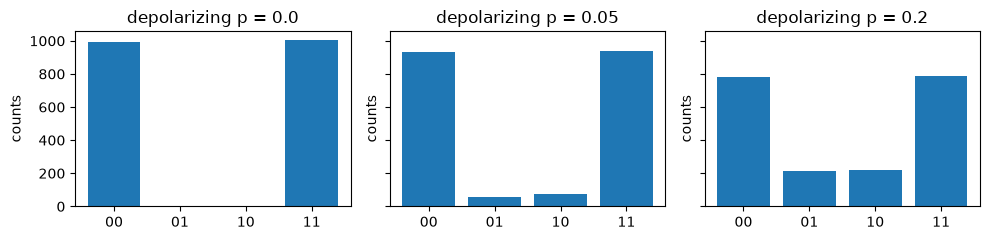

In [11]:
PAULIS = [X, Y, Z]

def maybe_error(sim, qubits, p, rng):
    """Depolarizing noise: with probability p, apply a random X, Y or Z to each listed qubit."""
    for q in qubits:
        if rng.random() < p:
            sim.gate(PAULIS[rng.integers(3)], q)
    return sim

def noisy_bell_counts(p, shots=2000, basis="Z", readout=0.0, seed=0):
    rng_ = np.random.default_rng(seed)
    counts = Counter()
    for _ in range(shots):                                    # one noise trajectory per shot
        sim = QSim(2).h(0); maybe_error(sim, [0], p, rng_)
        sim.cx(0, 1);       maybe_error(sim, [0, 1], p, rng_)
        if basis == "X":
            sim.h(0).h(1)                                     # measure in the X basis
        bits = list(next(iter(sim.measure(1, seed=int(rng_.integers(1e9))))))
        bits = [str(1 - int(b)) if rng_.random() < readout else b for b in bits]   # readout errors
        counts["".join(bits)] += 1
    return counts

def parity_expval(counts):
    """<ZZ> (or <XX> in the X basis): +1 if the two bits agree, -1 if they differ, averaged."""
    total = sum(counts.values())
    return sum((1 if b[0] == b[1] else -1) * k for b, k in counts.items()) / total

fig, axes = plt.subplots(1, 3, figsize=(10, 2.5), sharey=True)
for ax, p in zip(axes, [0.0, 0.05, 0.2]):
    plot_counts(noisy_bell_counts(p, seed=1), f"depolarizing p = {p}", ax=ax)
plt.show()

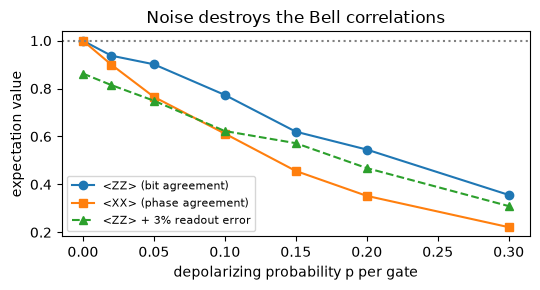

p=0.0   <ZZ>=+1.000  <XX>=+1.000
p=0.02  <ZZ>=+0.937  <XX>=+0.900
p=0.05  <ZZ>=+0.901  <XX>=+0.765
p=0.1   <ZZ>=+0.773  <XX>=+0.612
p=0.15  <ZZ>=+0.620  <XX>=+0.456
p=0.2   <ZZ>=+0.545  <XX>=+0.352
p=0.3   <ZZ>=+0.356  <XX>=+0.221


In [12]:
ps = [0.0, 0.02, 0.05, 0.1, 0.15, 0.2, 0.3]
zz = [parity_expval(noisy_bell_counts(p, shots=1500, basis="Z", seed=2)) for p in ps]
xx = [parity_expval(noisy_bell_counts(p, shots=1500, basis="X", seed=3)) for p in ps]
zz_ro = [parity_expval(noisy_bell_counts(p, shots=1500, basis="Z", readout=0.03, seed=4)) for p in ps]

plt.figure(figsize=(5.5, 3))
plt.plot(ps, zz, "o-", label="<ZZ> (bit agreement)")
plt.plot(ps, xx, "s-", label="<XX> (phase agreement)")
plt.plot(ps, zz_ro, "^--", label="<ZZ> + 3% readout error")
plt.axhline(1, c="gray", ls=":"); plt.xlabel("depolarizing probability p per gate")
plt.ylabel("expectation value"); plt.title("Noise destroys the Bell correlations"); plt.legend(fontsize=8)
plt.tight_layout(); plt.show()
for p, a, b in zip(ps, zz, xx):
    print(f"p={p:<5} <ZZ>={a:+.3f}  <XX>={b:+.3f}")

**What just happened?**
- Without noise only `00` and `11` appear. With noise, `01` and `10` creep in, and the correlations $\langle ZZ\rangle$ and $\langle XX\rangle$ shrink toward 0 (pure randomness).
- X and Y errors break the bit agreement; Z and Y errors break the phase agreement, which only the X-basis measurement can see. Real decoherence often damages phases first (T2 ≤ 2·T1).
- Readout errors add an extra drop even at p = 0.
- Deeper circuits have more gates, so the damage compounds. This is why NISQ algorithms must be short, and why notebook 03's QML models are limited on hardware.

## 6. Error mitigation vs quantum error correction

| | Error **mitigation** | Error **correction** (QEC) |
|---|---|---|
| Idea | run noisy circuits in clever ways and **post-process** the results to estimate the noise-free answer | encode one **logical qubit** in many **physical qubits** and **actively detect and fix** errors during the computation |
| Extra qubits | none (or few) | many (often about 100 or more physical qubits per logical qubit, depending on the code and error rates) |
| Cost | more shots; the shot cost grows exponentially with circuit size | more qubits, more gates, fast classical decoding |
| Gives | better *expectation values* on today's devices | in principle arbitrarily long, reliable computations ("**fault tolerance**") |
| Examples | zero-noise extrapolation (ZNE), readout-error mitigation, probabilistic error cancellation | repetition code, **surface code**, colour codes, qLDPC codes |

### 6.1 Error mitigation demo: zero-noise extrapolation (ZNE)

**What it is.** Deliberately run the circuit at *higher* noise levels (on hardware, for example by "folding" gates: replacing G with G G† G, which does nothing ideally but triples the noise), measure the result at each level, fit a curve, and **extrapolate back to zero noise**.

**Simple analogy.** You cannot weigh a cat that will not sit still, so you weigh yourself holding the cat, then holding two cats... and work backwards. More practically: measuring how a result *gets worse* as you add noise tells you what it would be *without* noise.

measured <XX> at noise scale 1, 2, 3: [0.82  0.632 0.512]
raw value (scale 1):          0.820
linear extrapolation to 0:    0.962
quadratic extrapolation to 0: 1.075
ideal value: 1.000


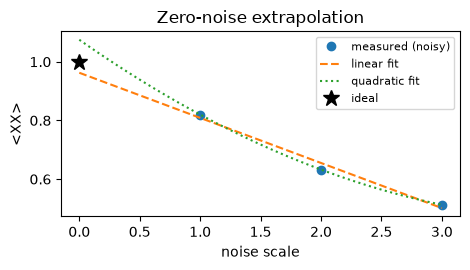

In [13]:
base_p = 0.05
scales = np.array([1, 2, 3])                                   # noise amplification factors
vals = np.array([parity_expval(noisy_bell_counts(base_p * s, shots=4000, basis="X", seed=10 + s)) for s in scales])

lin = np.polyfit(scales, vals, 1); quad = np.polyfit(scales, vals, 2)
print(f"measured <XX> at noise scale 1, 2, 3: {vals}")
print(f"raw value (scale 1):          {vals[0]:.3f}")
print(f"linear extrapolation to 0:    {np.polyval(lin, 0):.3f}")
print(f"quadratic extrapolation to 0: {np.polyval(quad, 0):.3f}")
print("ideal value: 1.000")

s_fine = np.linspace(0, 3, 50)
plt.figure(figsize=(4.8, 2.8))
plt.plot(scales, vals, "o", label="measured (noisy)")
plt.plot(s_fine, np.polyval(lin, s_fine), "--", label="linear fit")
plt.plot(s_fine, np.polyval(quad, s_fine), ":", label="quadratic fit")
plt.plot(0, 1, "k*", ms=12, label="ideal")
plt.xlabel("noise scale"); plt.ylabel("<XX>"); plt.title("Zero-noise extrapolation"); plt.legend(fontsize=8)
plt.tight_layout(); plt.show()

**What just happened?** The raw value is clearly below the ideal 1.0. The linear fit lands much closer; the quadratic fit overshoots above 1, which shows that the choice of fit model matters and brings its own error. The price: extra circuit runs, and the extrapolated value has a *larger* statistical spread (extrapolating amplifies shot noise). Mitigation helps for modest circuits, but its cost grows exponentially with circuit size, so it cannot replace error correction for large algorithms.

### 6.2 Error correction: the repetition code and the threshold

**What it is.** Classical computers fight noise with **redundancy**: store a bit three times (000 or 111) and take a majority vote. Quantum states cannot be copied (no-cloning) and cannot be looked at directly, so QEC instead measures **parity checks** (called **stabilizers**, or **syndrome** measurements), such as "are qubits 1 and 2 equal?", which reveal *where* an error happened without revealing the stored value. The **repetition code** protects against bit flips this way.

**The threshold idea.** If the physical error rate p is **below a threshold**, adding more qubits (a larger **code distance** d) makes the logical error rate drop *exponentially*. Above the threshold, adding qubits makes things worse. Below we simulate the simplest version (independent bit flips, perfect parity checks, majority-vote decoding), where the threshold is p = 0.5. For the realistic **surface code** with noisy gates and noisy measurements, the threshold is around 1%.

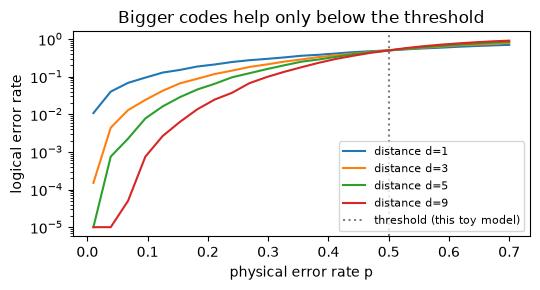

p=0.01: d=1: 1.0e-02, d=3: 3.2e-04, d=5: 1.0e-05, d=7: <5e-06 (no failures in 200,000 trials)
p=0.1: d=1: 9.9e-02, d=3: 2.8e-02, d=5: 8.5e-03, d=7: 2.6e-03


In [14]:
def repetition_logical_error(d, p, trials=20000, rng=rng):
    """Encode one logical bit in d physical bits, flip each with prob. p, decode by majority vote."""
    flips = rng.random((trials, d)) < p
    return np.mean(flips.sum(axis=1) > d // 2)

p_grid = np.linspace(0.01, 0.7, 25)
plt.figure(figsize=(5.5, 3))
for d in [1, 3, 5, 9]:
    plt.semilogy(p_grid, [max(repetition_logical_error(d, p), 1e-5) for p in p_grid], label=f"distance d={d}")
plt.axvline(0.5, c="gray", ls=":", label="threshold (this toy model)")
plt.xlabel("physical error rate p"); plt.ylabel("logical error rate"); plt.legend(fontsize=8)
plt.title("Bigger codes help only below the threshold"); plt.tight_layout(); plt.show()

for p in [0.01, 0.1]:
    rates = {d: repetition_logical_error(d, p, 200000) for d in [1, 3, 5, 7]}
    print(f"p={p}: " + ", ".join(f"d={d}: {r:.1e}" if r > 0 else f"d={d}: <5e-06 (no failures in 200,000 trials)" for d, r in rates.items()))

### 6.3 Logical vs physical qubits and the surface code

- A **physical qubit** is one real piece of hardware. A **logical qubit** is one protected qubit made from many physical qubits plus continuous error detection and correction.
- The **surface code** places data qubits on a 2-D grid, with "measure" qubits between them that repeatedly check the X-parity or Z-parity of their 4 neighbours. It needs only nearest-neighbour connections (good for chips), tolerates about 1% error rates, and a distance-d patch uses about $2d^2 - 1$ physical qubits (about 97 for d = 7).

```
 D---D---D        D = data qubit (stores the logical information together)
 | Z | X |        Z, X = measure qubits checking the Z- or X-parity of the 4 data qubits around them
 D---D---D        Every cycle (about 1 microsecond on superconducting chips) all checks are measured;
 | X | Z |        a classical DECODER reads the stream of check results and works out the errors.
 D---D---D
```

- **Below-threshold results (reported).** In 2024 Google reported a surface-code memory on its "Willow" chip in which increasing the code distance from 3 to 5 to 7 roughly halved the logical error rate at each step (Nature, "Quantum error correction below the surface code threshold"). Other groups (for example with trapped ions and neutral atoms) have reported logical qubits that outperform their physical qubits, and as of late 2026 several groups report steady progress on logical gates, not only memories. These are milestones, not yet useful computers.
- **Overheads.** Useful fault-tolerant algorithms (chemistry, Shor) are estimated to need hundreds to thousands of logical qubits and billions of logical operations, which means from hundreds of thousands to millions of physical qubits with today's codes. Newer codes (such as **qLDPC** codes) aim to cut this overhead.

## 7. AI for quantum vs quantum for AI

**What it is.** There are two very different directions:
- **Quantum for AI:** using quantum computers to do machine learning (notebook 03). Still mostly research, with no practical advantage shown.
- **AI for quantum:** using classical machine learning to build and run quantum computers better. This is **already useful today**, and it is where most AI engineers can contribute right now.

| AI for quantum: task | How ML helps | Status (as of late 2026, stated generally) |
|---|---|---|
| **Decoding** error-correction syndromes | neural networks (transformers, CNNs, GNNs) learn the real, messy noise of a device; must also be fast | reported to beat standard decoders in accuracy on real data (for example Google DeepMind's AlphaQubit, Nature 2024); speed for real-time use is an active challenge |
| **Calibration and control** | reinforcement learning and Bayesian optimisation tune pulse shapes and gate parameters automatically | used in labs and products to cut calibration time |
| **Readout** | classifiers turn raw analogue signals into 0/1 more accurately | common practice |
| **Circuit compilation and design** | RL and search find shorter circuits; ML predicts good variational ansatzes | research and some tools |
| **Code generation** | LLMs write and explain Qiskit / PennyLane code (for example IBM's Qiskit code assistant) | useful assistants; always verify outputs by simulation |
| **Characterisation** | learn noise models and Hamiltonians from measurement data | research, growing |
| **Classical simulation** | neural-network quantum states and tensor networks simulate quantum systems | a strong classical competitor to quantum hardware |

### 7.1 Demo: a learned decoder beats the textbook rule under correlated noise

**Setup.** A distance-5 repetition code. Parity checks compare neighbouring data qubits (4 syndrome bits). The textbook **minimum-weight** decoder assumes errors are independent and picks the *smallest* set of flips that explains the syndrome. Our simulated device also has **correlated** errors: sometimes two neighbouring qubits flip together (like crosstalk), which the textbook rule does not know about. A small neural network (`MLPClassifier`) learns the decoder from simulated syndrome data.

In [15]:
D = 5                                                     # data qubits

def sample_errors(n, p_ind, p_pair, rng):
    """Independent flips with prob. p_ind, plus (with prob. p_pair) a burst flipping two neighbours."""
    e = rng.random((n, D)) < p_ind
    burst = rng.random(n) < p_pair
    start = rng.integers(0, D - 1, n)
    e[burst, start[burst]] ^= True; e[burst, start[burst] + 1] ^= True
    return e.astype(int)

def syndrome(e):
    return (e[:, :-1] ^ e[:, 1:])                           # neighbour parity checks

def candidates(s):
    """The two error patterns consistent with a syndrome (one is the complement of the other)."""
    first = np.zeros((len(s), D), dtype=int)
    for i in range(1, D):
        first[:, i] = first[:, i - 1] ^ s[:, i - 1]
    return first, 1 - first

def min_weight_decoder(s):
    a, b = candidates(s)
    return np.where((a.sum(1) <= b.sum(1))[:, None], a, b)

def logical_error_rate(e, e_hat):
    return np.mean(e_hat[:, 0] != e[:, 0])                 # wrong candidate = logical flip

for name, p_ind, p_pair in [("independent noise", 0.12, 0.0), ("correlated noise ", 0.06, 0.35)]:
    e_train, e_test = sample_errors(20000, p_ind, p_pair, rng), sample_errors(20000, p_ind, p_pair, rng)
    s_train, s_test = syndrome(e_train), syndrome(e_test)
    mlp = MLPClassifier(hidden_layer_sizes=(32,), max_iter=500, random_state=SEED)
    mlp.fit(s_train, candidates(s_train)[0][:, 0] != e_train[:, 0])   # learn: "is the first candidate wrong?"
    a, b = candidates(s_test)
    e_nn = np.where(mlp.predict(s_test)[:, None], b, a)
    print(f"{name}: logical error  min-weight {logical_error_rate(e_test, min_weight_decoder(s_test)):.4f}"
          f"   learned (MLP) {logical_error_rate(e_test, e_nn):.4f}")

independent noise: logical error  min-weight 0.0141   learned (MLP) 0.0141


correlated noise : logical error  min-weight 0.0558   learned (MLP) 0.0433


**What just happened?** With independent noise, the textbook rule is already the best possible, and the network matches it. With correlated bursts, the network learns that "two neighbours flipped together" is common and makes fewer logical errors. Real neural decoders do the same thing at a much larger scale, on many rounds of noisy measurements, using data from the actual chip. The hard engineering part is speed: a superconducting chip produces a new round of syndromes about every microsecond.

## 8. Realistic industry use cases (with honest caveats)

| Area | What people hope for | Honest caveat (as of late 2026) | Timeline view |
|---|---|---|---|
| **Chemistry and materials simulation** (catalysts, batteries, drug binding, nitrogen fixation) | accurate energies for molecules where classical methods struggle (strongly correlated electrons) | the strongest long-term case, but needs fault-tolerant machines; classical methods (DFT, coupled cluster, tensor networks, ML force fields) keep improving; many molecules do not need a quantum computer at all | most experts expect useful advantage only with error-corrected hardware |
| **Physics simulation** (magnets, high-energy and condensed-matter models) | study dynamics that classical computers cannot | early "beyond classical" claims exist for special models; usefulness for industry still to be shown | first scientific value likely earliest here |
| **Optimisation** (logistics, scheduling, portfolio) | better or faster solutions with QAOA or quantum annealing | no proven advantage; classical solvers (Gurobi, CP-SAT, heuristics) are extremely strong; most speedups are at best quadratic | uncertain |
| **Finance** (option pricing, risk) | quadratic speedup in Monte Carlo via amplitude estimation | resource estimates need fault-tolerant machines with fast gates; loading probability distributions is costly | long term |
| **Machine learning** | faster training or better models | see notebook 03: dequantization, data loading, barren plateaus | research |
| **Cryptography** | breaking RSA/ECC (a threat, not a product) | the reason for the PQC migration now (section 9) | timeline uncertain, but migration takes years |
| **Quantum sensing and networking** (related fields) | more precise sensors (clocks, magnetometers), secure key distribution | already commercial in some niches; different from quantum *computing* | today |

**How to read a "quantum advantage" press release:** Is the task useful? What is the best classical baseline, and was it tuned? How many physical vs logical qubits? What are the error rates? Has anyone reproduced it, or found a classical simulation since?

## 9. Post-quantum cryptography: why AI engineers should care

**What it is.** **Post-quantum cryptography (PQC)** is a set of *classical* encryption and signature algorithms that run on today's computers but are believed to resist attacks by future quantum computers (Shor's algorithm breaks RSA and elliptic curves; notebook 02).

**The NIST standards (August 2024).**

| Standard | Name | Use | Based on |
|---|---|---|---|
| FIPS 203 | **ML-KEM** (from CRYSTALS-Kyber) | key exchange / encryption (for example in TLS) | module lattices (learning with errors) |
| FIPS 204 | **ML-DSA** (from CRYSTALS-Dilithium) | digital signatures | module lattices |
| FIPS 205 | **SLH-DSA** (from SPHINCS+) | digital signatures (conservative backup) | hash functions |

NIST has also selected further algorithms (FN-DSA, from Falcon, for signatures; HQC as a backup key-exchange scheme), and has published guidance to phase out RSA and ECC in the 2030s. Many browsers and large web services already use **hybrid** key exchange (a classical algorithm plus ML-KEM together) as of late 2026.

**"Harvest now, decrypt later" (HNDL).** An attacker records encrypted traffic or steals encrypted backups **today**, then decrypts them years later with a quantum computer. Anything that must stay secret for 10+ years is at risk now.

**Why this matters for AI engineers specifically.**
- **Model weights** are valuable intellectual property and are often moved between clouds, regions and partners.
- **Training data** (medical records, user chats, proprietary documents) may need to stay confidential for decades.
- **API traffic** to LLM services carries prompts and private data; inference often runs across many networks.
- **Signed artefacts**: model files, containers and software updates rely on digital signatures (supply-chain security); forged signatures could inject backdoored models.
- **Long-lived systems**: embedded and edge AI devices sold today may still run in 2040.

**What to do (checklist):** keep an **inventory** of where cryptography is used (TLS, VPNs, storage encryption, signing, key management); design for **crypto agility** (algorithms can be swapped by configuration); prefer libraries and cloud services that support hybrid PQC; prioritise long-lived secrets; follow your security team and national guidance (NIST, and equivalents in other countries). Symmetric encryption (AES-256) and hashes (SHA-256/384) remain fine.

### 9.1 Toy demo: the idea behind lattice cryptography (learning with errors)

**What it is.** ML-KEM is built on the **learning with errors (LWE)** problem (in a structured "module" form): given many noisy linear equations $b = A s + e \pmod q$ with small random errors $e$, find the secret $s$. Without the errors it is easy (Gaussian elimination). With the errors it is believed to be hard, even for quantum computers.

**Simple analogy.** Solving a system of equations where every right-hand side has been nudged by a small random amount. A few nudges turn an easy school exercise into a problem no known algorithm, classical or quantum, solves efficiently at large sizes.

The toy below (Regev-style, encrypting single bits) uses tiny numbers and is **completely insecure**; it only shows the mechanism. Never write your own cryptography for real use.

In [16]:
q, n_dim, m = 97, 8, 20                                    # toy sizes (real schemes use far larger, structured ones)
s_secret = rng.integers(0, q, n_dim)                       # private key
A = rng.integers(0, q, (m, n_dim))
e = rng.integers(-1, 2, m)                                 # small errors in {-1, 0, 1}
b = (A @ s_secret + e) % q                                 # public key: (A, b)

def encrypt(bit):
    r = rng.integers(0, 2, m)                              # random subset of the public equations
    return (r @ A) % q, (r @ b + bit * (q // 2)) % q

def decrypt(u, v):
    d = (v - u @ s_secret) % q                             # = bit * q/2 + (small error sum)
    return int(q // 4 < d < 3 * q // 4)                    # close to q/2 -> 1, close to 0 -> 0

bits = rng.integers(0, 2, 20)
decoded = [decrypt(*encrypt(bit)) for bit in bits]
print("message bits:", bits)
print("decrypted   :", np.array(decoded), " all correct:", np.array_equal(bits, decoded))

def solve_mod(M, rhs, q):
    """Gaussian elimination modulo a prime q (square system). Returns x with M x = rhs (mod q)."""
    M = np.column_stack([M % q, rhs % q]).astype(np.int64); k = len(M)
    for col in range(k):
        piv = next(r for r in range(col, k) if M[r, col] % q != 0)   # find a usable pivot row
        M[[col, piv]] = M[[piv, col]]
        M[col] = (M[col] * pow(int(M[col, col]), -1, q)) % q
        for r in range(k):
            if r != col:
                M[r] = (M[r] - M[r, col] * M[col]) % q
    return M[:, -1]

# Why the small errors matter: use the first n_dim equations and solve them exactly (mod q)
b_no_error = (A @ s_secret) % q
print("solve WITHOUT errors -> recovers the secret:", np.array_equal(solve_mod(A[:n_dim], b_no_error[:n_dim], q), s_secret))
print("solve WITH errors    -> recovers the secret:", np.array_equal(solve_mod(A[:n_dim], b[:n_dim], q), s_secret))

message bits: [0 0 1 1 1 0 1 1 0 0 1 1 0 1 0 0 1 0 1 0]
decrypted   : [0 0 1 1 1 0 1 1 0 0 1 1 0 1 0 0 1 0 1 0]  all correct: True
solve WITHOUT errors -> recovers the secret: True
solve WITH errors    -> recovers the secret: False


## 10. Trying real hardware through the cloud (described, not run)

Several providers give cloud access to real quantum computers. Most offer a free or low-cost tier, simulators, and pay-per-shot or reserved access for larger jobs. You need an account and an API token, which is why **nothing below is executed** in this notebook. APIs change often; follow each provider's current documentation.

| Provider | Hardware (examples) | Typical SDK |
|---|---|---|
| **IBM Quantum Platform** | IBM superconducting processors (100+ qubits) | Qiskit + `qiskit-ibm-runtime` |
| **Amazon Braket** | several vendors (for example IonQ, Rigetti, IQM, QuEra) | Amazon Braket SDK (also PennyLane and Qiskit plugins) |
| **Azure Quantum** | several vendors (for example Quantinuum, IonQ, Pasqal, Rigetti) | Q#, Qiskit or Cirq through `azure-quantum` |
| Others | vendor clouds (for example Quantinuum, IonQ, IQM, Pasqal) and national research centres | vendor SDKs |

**IBM Quantum with Qiskit (sketch):**

```python
from qiskit import QuantumCircuit
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler

service = QiskitRuntimeService()                      # reads your saved IBM Quantum API token
backend = service.least_busy(operational=True, simulator=False)

qc = QuantumCircuit(2); qc.h(0); qc.cx(0, 1); qc.measure_all()
isa_qc = generate_preset_pass_manager(backend=backend, optimization_level=1).run(qc)  # map to the chip's gates/qubits
job = Sampler(mode=backend).run([isa_qc], shots=1000)
print(job.result()[0].data.meas.get_counts())         # expect mostly 00 and 11, plus some noise
```

**Amazon Braket (sketch):**

```python
from braket.circuits import Circuit
from braket.devices import LocalSimulator            # free local simulator
# from braket.aws import AwsDevice                   # real devices: AwsDevice("<device ARN>")

bell = Circuit().h(0).cnot(0, 1)
result = LocalSimulator().run(bell, shots=1000).result()
print(result.measurement_counts)
```

**Azure Quantum (sketch):**

```python
from azure.quantum import Workspace
from azure.quantum.qiskit import AzureQuantumProvider

workspace = Workspace(resource_id="<your workspace resource id>", location="<region>")
provider = AzureQuantumProvider(workspace)
backend = provider.get_backend("<target name, e.g. a vendor simulator>")
job = backend.run(qc, shots=1000)                    # qc: a Qiskit circuit
print(job.result().get_counts())
```

**Good habits:** always run on a simulator first; check the queue and the cost; transpile and look at the circuit depth on the real chip (it often grows a lot); compare hardware counts with the ideal simulation and with a noisy simulation.

## 11. Career and learning roadmap

**Who hires for quantum + AI?** Quantum hardware and software companies, cloud providers, national labs and universities, and research teams in chemistry, pharma, finance and security. Many roles are not "quantum physicist": they are software, ML, HPC, compiler, control-systems and security engineers.

| Role | What you do | Skills on top of AI engineering |
|---|---|---|
| Quantum software engineer | SDKs, compilers, simulators, cloud services | linear algebra, Qiskit/PennyLane/Cirq internals, performance engineering |
| Quantum ML researcher | new QML models, honest benchmarks | this track, Schuld & Petruccione, research methods |
| ML for quantum hardware | decoders, calibration, control, readout | deep learning, RL, real-time / low-latency systems, signal processing |
| Quantum algorithms / applications scientist | chemistry, optimisation, resource estimates | domain science (chemistry, OR, finance), complexity |
| PQC / security engineer | migrate systems to post-quantum crypto | applied cryptography, TLS, key management, compliance |

```mermaid
flowchart TD
    A[Maths: linear algebra,<br/>probability, complex numbers] --> B[Notebook 01:<br/>qubits, gates, simulator]
    B --> C[Notebook 02:<br/>algorithms, VQE, QAOA]
    C --> D[Notebook 03:<br/>QML and its limits]
    D --> E[Notebook 04:<br/>tools, hardware, noise, PQC]
    E --> F{Pick a direction}
    F --> G[Quantum software:<br/>Qiskit or PennyLane contributions]
    F --> H[ML for quantum:<br/>decoders, control, Stim]
    F --> I[Applications:<br/>chemistry or optimisation]
    F --> J[Security:<br/>PQC migration]
    G & H & I & J --> K[Build a public project,<br/>run on real cloud hardware,<br/>read Nielsen and Chuang]
```

**A practical 3-month plan (suggestion):**
1. Month 1: notebooks 01-02 of this track, Nielsen & Chuang chapters 1-2 and 4-6, and the IBM Quantum Learning "Basics of quantum information" course.
2. Month 2: notebook 03, then the PennyLane QML demos; reproduce one QML paper *with classical baselines* (use [24_Research_Methods](../24_Research_Methods/README.md)).
3. Month 3: notebook 04, run one experiment on free cloud hardware, and do one project that combines your AI skills with quantum (for example a neural decoder trained on Stim-simulated data, or an honest benchmark of a quantum kernel vs classical kernels).

## 12. Recap (cheat sheet)

| Topic | Key point |
|---|---|
| Qiskit vs PennyLane | Qiskit: circuits, primitives, IBM hardware. PennyLane: differentiable circuits, QML. Qiskit prints qubit 0 on the **right** |
| Hardware modalities | superconducting (fast, cryogenic), trapped ion (accurate, slow), neutral atom (large arrays), photonic (light, loss), spin (silicon, early), topological (early research) |
| Noise | decoherence (T1, T2), gate errors, readout errors; depolarizing noise shrinks correlations toward 0 |
| Error mitigation | post-processing tricks such as ZNE; more shots, no extra qubits; does not scale to large circuits |
| Error correction | logical qubit = many physical qubits + syndrome measurements + decoder; works below a threshold |
| Surface code | 2-D grid, about $2d^2-1$ qubits per logical qubit, threshold about 1%; below-threshold operation reported since 2024 |
| AI for quantum | decoders, calibration, readout, compilation, code generation: useful today |
| Quantum for AI | research stage, no practical advantage yet |
| Industry | chemistry/materials is the strongest long-term case; optimisation and finance are uncertain |
| PQC | ML-KEM (FIPS 203), ML-DSA (FIPS 204), SLH-DSA (FIPS 205); harvest now, decrypt later; crypto agility |
| Cloud access | IBM Quantum, Amazon Braket, Azure Quantum; simulate first, then run small jobs |

## 13. Interview questions

1. **Name three qubit modalities and one trade-off each.** Superconducting (fast gates, short coherence, needs dilution fridges); trapped ions (high fidelity and all-to-all connectivity, slow gates); neutral atoms (large reconfigurable arrays, slower cycles and atom loss).
2. **What are T1 and T2?** T1: energy relaxation time ($\lvert1\rangle\to\lvert0\rangle$). T2: dephasing time, how long phase coherence survives.
3. **Error mitigation vs error correction?** Mitigation post-processes noisy results (more shots, no extra qubits, limited scale); correction encodes logical qubits in many physical ones and fixes errors during the computation.
4. **What does "below threshold" mean?** The physical error rate is low enough that a bigger code makes the logical error rate smaller (exponentially in the code distance).
5. **Physical vs logical qubits?** Physical: real hardware qubits. Logical: an error-protected qubit built from many physical qubits (about $2d^2-1$ for a distance-d surface code).
6. **Where can ML help quantum computing today?** Decoding syndromes, calibration and control, readout classification, compilation, noise characterisation, and LLM coding assistants.
7. **Why can a learned decoder beat minimum-weight decoding?** It learns the device's real error statistics (for example correlated errors), which minimum-weight decoding ignores.
8. **What is ML-KEM and why migrate now?** NIST's lattice-based key-encapsulation standard (FIPS 203); data recorded today can be decrypted later ("harvest now, decrypt later"), and migrations take years.
9. **Why should an AI team care about PQC?** Model weights, training data and API traffic are long-lived secrets, and model artefacts depend on signatures for supply-chain security.
10. **Qiskit shows `001` after an X on qubit 0. Why?** Qiskit is little-endian: qubit 0 is the right-most bit.

## 14. Further reading

- M. A. Nielsen and I. L. Chuang, *Quantum Computation and Quantum Information*, Cambridge University Press, 2010 (chapter 10: quantum error correction).
- Qiskit documentation (docs.quantum.ibm.com) and IBM Quantum Learning (the successor of the Qiskit textbook).
- PennyLane documentation and QML demos (pennylane.ai/qml).
- Cirq, Amazon Braket, Azure Quantum, CUDA-Q and Stim documentation.
- J. Preskill, "Quantum Computing in the NISQ era and beyond", *Quantum* 2, 79 (2018), arXiv:1801.00862.
- M. Schuld and F. Petruccione, *Machine Learning with Quantum Computers*, Springer, 2nd ed. 2021.
- J. R. McClean et al., "Barren plateaus in quantum neural network training landscapes", *Nature Communications* (2018), arXiv:1803.11173.
- V. Havlíček et al., "Supervised learning with quantum-enhanced feature spaces", *Nature* (2019), arXiv:1804.11326.
- A. G. Fowler et al., "Surface codes: Towards practical large-scale quantum computation", *Physical Review A* (2012).
- Google Quantum AI and collaborators, "Quantum error correction below the surface code threshold", *Nature* (published online December 2024).
- J. Bausch et al. (Google DeepMind / Google Quantum AI), "Learning high-accuracy error decoding for quantum processors", *Nature* (2024).
- K. Temme, S. Bravyi and J. M. Gambetta, "Error mitigation for short-depth quantum circuits", *Physical Review Letters* (2017) (zero-noise extrapolation).
- NIST FIPS 203, 204 and 205 (2024), and NIST's post-quantum cryptography project pages.
- O. Regev, "On lattices, learning with errors, random linear codes, and cryptography", STOC 2005.

## Where to go next

- Back to the track overview: [README.md](README.md) and the study notes [notes/25_Quantum_AI.md](notes/25_Quantum_AI.md).
- Security background for AI systems: [19_AI_Ethics_and_Safety](../19_AI_Ethics_and_Safety/).
- Running honest experiments and benchmarks: [24_Research_Methods](../24_Research_Methods/README.md).